# Recovering coherent errors from randomized-compiling labels, in PennyLane

This notebook implements the method of
[arXiv:2607.26756](https://arxiv.org/abs/2607.26756) with PennyLane transforms.

**The idea in one line.** Randomized compiling (RC) dresses each gate with random Paulis so that a
coherent error averages into a stochastic one. Standard RC then throws the random choices (the
*labels*) away. The paper shows the coherent-error information is not destroyed but moved into the
labels: keep them, and the error angle can be read back out at full Fisher information.

Contents:
1. Standard RC with `pauli_twirl` (a transform PennyLane does not ship)
2. Keeping the labels with `sign_label_twirl`
3. Recovering the error angle under noise, with finite shots
4. The Fisher-information conservation law, with exact autodiff and PennyLane's Fisher transforms
5. No washout with depth, with `qp.gradients.quantum_fisher`
6. Two-qubit ZZ crosstalk recovered from owned labels
7. Re-analysing the paper's IBM hardware records (`ibm_marrakesh`)

Every number and figure below is computed by the code in this notebook. The repository's numpy
engine (`core/`) is the reference; `pennylane_impl/tests/` checks this package against it.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # pennylane_impl/, so labeled_rc is importable

import numpy as np
import matplotlib.pyplot as plt
import pennylane as qp
import labeled_rc as lrc

print("PennyLane", qp.__version__, "| NumPy", np.__version__)

PennyLane 0.45.1 | NumPy 2.5.4


## 1. Standard randomized compiling with `pauli_twirl`

`lrc.pauli_twirl` is a `qp.transform`. For every CNOT/CZ it draws a random Pauli `P` on the two
wires, inserts `P` before the gate and `P' = G P G†` after it (computed by conjugation, not from a
table), and averages over `num_samples` twirled circuits. Without noise every twirled circuit equals
the original.

Here a coherent `IsingZZ(0.08)` over-rotation follows every CNOT (attached with `qp.NoiseModel`).
Pairs of CNOTs ideally cancel, so any deviation from the starting state is error. Coherent errors add
in amplitude, so the error grows quadratically with depth; after twirling it behaves like a Pauli
channel and grows linearly.

k= 1  coherent error=0.0032  twirled error=0.0032
k= 2  coherent error=0.0127  twirled error=0.0062
k= 4  coherent error=0.0501  twirled error=0.0120
k= 8  coherent error=0.1881  twirled error=0.0252
k=16  coherent error=0.5861  twirled error=0.0511


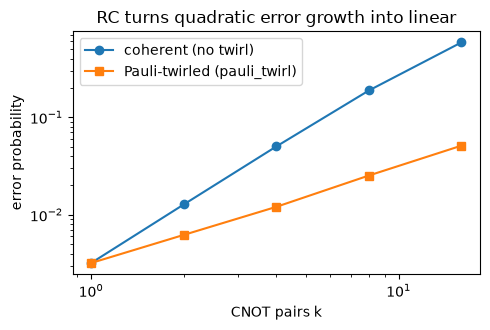

In [2]:
eps = 0.08
zz_error = qp.NoiseModel({qp.noise.op_eq(qp.CNOT): lambda op, **kw: qp.IsingZZ(eps, wires=op.wires)})
dev2 = qp.device("default.mixed", wires=2)

def cnot_pairs(k):
    @qp.qnode(dev2)
    def circuit():
        qp.Hadamard(0); qp.Hadamard(1)
        for _ in range(k):
            qp.CNOT(wires=[0, 1]); qp.CNOT(wires=[0, 1])
        qp.Hadamard(0); qp.Hadamard(1)
        return qp.probs(wires=[0, 1])
    return circuit

depths = [1, 2, 4, 8, 16]
coherent = [1 - float(qp.add_noise(cnot_pairs(k), zz_error)()[0]) for k in depths]
twirled = [1 - float(qp.add_noise(lrc.pauli_twirl(cnot_pairs(k), num_samples=300, seed=1), zz_error)()[0])
           for k in depths]

for k, c, t in zip(depths, coherent, twirled):
    print(f"k={k:2d}  coherent error={c:.4f}  twirled error={t:.4f}")

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(depths, coherent, "o-", label="coherent (no twirl)")
ax.loglog(depths, twirled, "s-", label="Pauli-twirled (pauli_twirl)")
ax.set_xlabel("CNOT pairs k"); ax.set_ylabel("error probability")
ax.set_title("RC turns quadratic error growth into linear")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Keeping the labels with `sign_label_twirl`

The paper's construction, as in its hardware experiment: prepare |+⟩, apply `L` coherent Z-errors
`RZ(θ)`, measure ⟨Y⟩. The twirl dresses error location `l` with `X … X` when its label `s_l = −1`
(since `X RZ(θ) X = RZ(−θ)`), so each instance gives ⟨Y⟩ = v · sin(θ Σ s_l).

The labels are generated by the caller and passed in, so they are *owned* and never lost.
Standard RC keeps only the label-averaged mean, which is zero at full twirl. The label–outcome
correlation C(L) = E[(Σ s) ⟨Y⟩] keeps the signal, and it grows with depth.

Noise: phase damping + depolarizing after every error layer, symmetric readout bit flip via
`meas_map`. (Readout error is attached through the noise model because `default.mixed`'s own
`readout_prob` argument currently raises a `TypeError` on execution; see PennyLane issue
[#9612](https://github.com/PennyLaneAI/pennylane/issues/9612).)

L= 1  v(L)=0.9637  marginal mean=+0.0024  label correlation C=0.0482
L= 2  v(L)=0.9476  marginal mean=+0.0000  label correlation C=0.0937


L= 4  v(L)=0.9163  marginal mean=-0.0032  label correlation C=0.1762


L= 8  v(L)=0.8568  marginal mean=+0.0000  label correlation C=0.3565

L=16  v(L)=0.7491  marginal mean=-0.0108  label correlation C=0.6311

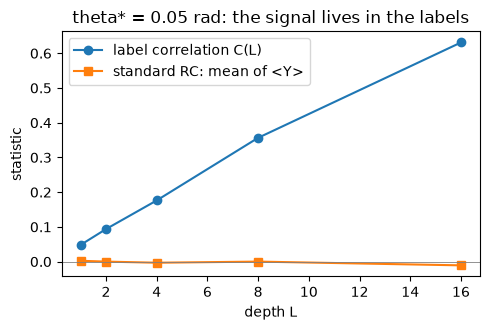

In [3]:
def layer_noise(op, **kw):
    qp.PhaseDamping(0.02, wires=op.wires)
    qp.DepolarizingChannel(0.005, wires=op.wires)

def readout_noise(op, **kw):
    qp.BitFlip(0.01, wires=op.wires)

noise = qp.NoiseModel({qp.noise.op_eq(qp.RZ): layer_noise},
                      meas_map={qp.noise.meas_eq(qp.expval): readout_noise})
dev1 = qp.device("default.mixed", wires=1)

theta_star = 0.05
Ls = [1, 2, 4, 8, 16]
C, marg, vis = [], [], []
for L in Ls:
    signs = lrc.sample_signs(400, L, seed=L)
    y = np.asarray(qp.add_noise(lrc.sign_label_twirl(lrc.signal_tape_qnode(dev1, L), signs=signs), noise)(theta_star))
    v = float(qp.add_noise(lrc.visibility_qnode(dev1, L), noise)())
    C.append(lrc.label_correlation(signs.sum(axis=1), y)); marg.append(lrc.marginal_mean(y)); vis.append(v)
    print(f"L={L:2d}  v(L)={v:.4f}  marginal mean={marg[-1]:+.4f}  label correlation C={C[-1]:.4f}")

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.plot(Ls, C, "o-", label="label correlation C(L)")
ax.plot(Ls, marg, "s-", label="standard RC: mean of <Y>")
ax.set_xlabel("depth L"); ax.set_ylabel("statistic"); ax.axhline(0, color="gray", lw=0.6)
ax.set_title(f"theta* = {theta_star} rad: the signal lives in the labels")
ax.legend(); plt.tight_layout(); plt.show()

## 3. Recovering θ under noise with finite shots

The protocol of the paper's hardware run, scaled down: for each injected θ* and depth L, 40 twirl
instances × 2000 shots, a visibility reference at the same depth, and the least-squares fit of
⟨Y⟩ᵢ = v(L) sin(θ mᵢ) with mᵢ = Σ s. Intervals are 95% bootstrap over instances.

theta*=0.00  L= 1  theta_hat=+0.0012  95% CI=[-0.0052, +0.0076]
theta*=0.00  L= 4  theta_hat=+0.0020  95% CI=[-0.0016, +0.0057]
theta*=0.00  L=16  theta_hat=-0.0006  95% CI=[-0.0034, +0.0022]
theta*=0.05  L= 1  theta_hat=+0.0480  95% CI=[+0.0409, +0.0553]
theta*=0.05  L= 4  theta_hat=+0.0512  95% CI=[+0.0476, +0.0542]
theta*=0.05  L=16  theta_hat=+0.0491  95% CI=[+0.0458, +0.0517]
theta*=0.10  L= 1  theta_hat=+0.0981  95% CI=[+0.0925, +0.1039]
theta*=0.10  L= 4  theta_hat=+0.1012  95% CI=[+0.0987, +0.1041]
theta*=0.10  L=16  theta_hat=+0.0997  95% CI=[+0.0965, +0.1031]
theta*=0.20  L= 1  theta_hat=+0.1931  95% CI=[+0.1865, +0.1998]
theta*=0.20  L= 4  theta_hat=+0.2019  95% CI=[+0.1972, +0.2060]
theta*=0.20  L=16  theta_hat=+0.1968  95% CI=[+0.1931, +0.2006]
theta*=0.30  L= 1  theta_hat=+0.3040  95% CI=[+0.2969, +0.3107]
theta*=0.30  L= 4  theta_hat=+0.3009  95% CI=[+0.2963, +0.3063]
theta*=0.30  L=16  theta_hat=+0.2999  95% CI=[+0.2959, +0.3038]
max |theta_hat - theta*| = 0.0069 rad


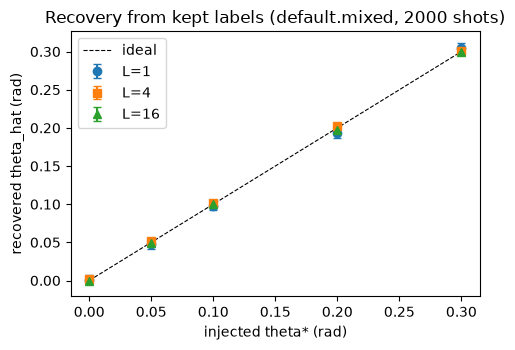

In [4]:
dev_shots = qp.device("default.mixed", wires=1, seed=2026)
thetas = [0.0, 0.05, 0.1, 0.2, 0.3]
depths_fit = [1, 4, 16]
results = {}
for L in depths_fit:
    ref = qp.set_shots(qp.add_noise(lrc.visibility_qnode(dev_shots, L), noise), 2000)
    v = float(np.mean([ref() for _ in range(10)]))
    for th in thetas:
        signs = lrc.sample_signs(40, L, seed=int(1000 * th) + L)
        circ = qp.set_shots(qp.add_noise(lrc.sign_label_twirl(lrc.signal_tape_qnode(dev_shots, L), signs=signs), noise), 2000)
        y = np.asarray(circ(th))
        results[(th, L)] = lrc.bootstrap_theta(signs.sum(axis=1), y, v, num_boot=400, seed=0)

worst = 0.0
for (th, L), (est, (lo, hi)) in sorted(results.items()):
    worst = max(worst, abs(est - th))
    print(f"theta*={th:.2f}  L={L:2d}  theta_hat={est:+.4f}  95% CI=[{lo:+.4f}, {hi:+.4f}]")
print(f"max |theta_hat - theta*| = {worst:.4f} rad")

fig, ax = plt.subplots(figsize=(5, 3.6))
for L, mk in zip(depths_fit, "os^"):
    est = [results[(th, L)][0] for th in thetas]
    err = np.array([[results[(th, L)][0] - results[(th, L)][1][0], results[(th, L)][1][1] - results[(th, L)][0]] for th in thetas]).T
    ax.errorbar(thetas, est, yerr=err, fmt=mk, capsize=3, label=f"L={L}")
ax.plot([0, 0.3], [0, 0.3], "k--", lw=0.8, label="ideal")
ax.set_xlabel("injected theta* (rad)"); ax.set_ylabel("recovered theta_hat (rad)")
ax.set_title("Recovery from kept labels (default.mixed, 2000 shots)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. The conservation law, with exact derivatives

Put the label in an ancilla (`lrc.joint_label_qnode`): the ancilla holds label +1 with probability
(1+μ)/2 and, when it is |1⟩, the error is dressed with X. Measuring both gives p(s, b); measuring the
system alone gives what standard RC keeps. With `qp.jacobian` the three Fisher terms are exact:

F_joint = F_marg + Δ,  with F_joint = F₀ = 1 for every twirl strength T = 1 − |μ|.

The paper's closed forms F_marg = (1−T)², Δ = 2T − T² are leading order in θ; at finite θ the exact
marginal is μ² cos²θ / (1 − μ² sin²θ), which the autodiff result reproduces.

theta=0.0: max |F_joint - (F_marg + Delta)| = 2.22e-16,  max |F_joint - 1| = 6.66e-16
theta=0.3: max |F_joint - (F_marg + Delta)| = 3.33e-16,  max |F_joint - 1| = 6.66e-16
theta=0.3: max |F_marg - exact closed form| = 7.77e-16


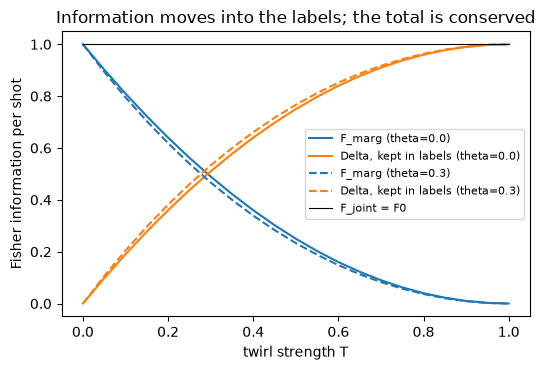

In [5]:
dev_q = qp.device("default.qubit", wires=2)
Ts = np.linspace(0, 1, 21)
plt.figure(figsize=(5.5, 3.8))
for th, style in [(0.0, "-"), (0.3, "--")]:
    rows = [lrc.fisher_decomposition(lrc.joint_label_qnode(dev_q, 1 - T), th) for T in Ts]
    Fj, Fm, D = map(np.array, zip(*rows))
    print(f"theta={th}: max |F_joint - (F_marg + Delta)| = {np.max(np.abs(Fj - Fm - D)):.2e},"
          f"  max |F_joint - 1| = {np.max(np.abs(Fj - 1)):.2e}")
    if th == 0.3:
        exact = np.array([lrc.exact_marginal_fisher(th, 1 - T) for T in Ts])
        print(f"theta=0.3: max |F_marg - exact closed form| = {np.max(np.abs(Fm - exact)):.2e}")
    plt.plot(Ts, Fm, style, color="C0", label=f"F_marg (theta={th})")
    plt.plot(Ts, D, style, color="C1", label=f"Delta, kept in labels (theta={th})")
plt.plot(Ts, np.ones_like(Ts), color="k", lw=0.8, label="F_joint = F0")
plt.xlabel("twirl strength T"); plt.ylabel("Fisher information per shot")
plt.title("Information moves into the labels; the total is conserved")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

The same statement with PennyLane's own Fisher-information transforms, independently of the
Jacobian-based decomposition above: `qp.gradients.classical_fisher` of the joint (label, outcome)
distribution equals `qp.gradients.quantum_fisher` of the untwirled error, at every twirl strength.

In [6]:
from pennylane import numpy as pnp

dev_1 = qp.device("default.qubit", wires=1)

@qp.qnode(dev_1)
def untwirled_state(theta):
    qp.Hadamard(0)
    qp.RZ(theta, wires=0)
    return qp.state()

for th in (0.0, 0.3):
    t = pnp.array(th, requires_grad=True)
    F0 = float(np.squeeze(qp.gradients.quantum_fisher(untwirled_state)(t)))
    gaps = [abs(float(np.squeeze(qp.gradients.classical_fisher(lrc.joint_label_qnode(dev_q, 1 - T))(t))) - F0)
            for T in Ts]
    print(f"theta={th}: quantum_fisher F0 = {F0:.12f},  max |classical_fisher(joint) - F0| over T = {max(gaps):.1e}")

theta=0.0: quantum_fisher F0 = 1.000000000000,  max |classical_fisher(joint) - F0| over T = 4.4e-16
theta=0.3: quantum_fisher F0 = 1.000000000000,  max |classical_fisher(joint) - F0| over T = 4.4e-16


## 5. No washout with depth

The paper's depth model (`core/circuits.trotter_single_qubit`): start in |0⟩ and repeat
`RX(α)` followed by the coherent error `RZ(s_l θ)` for `L` cycles. At θ = 0 the paper predicts

- with labels: E_s[F_Q] = Σ sin²(lα), which grows like L/2;
- without twirling: F_Q = (Σ sin(lα))², which stays bounded.

Below, both are computed with `qp.gradients.quantum_fisher` on the PennyLane circuit (the labeled
value by exact enumeration of all 2^L label vectors) and compared with the closed forms.

max |quantum_fisher - closed form| for L = 1..10: 5.3e-15


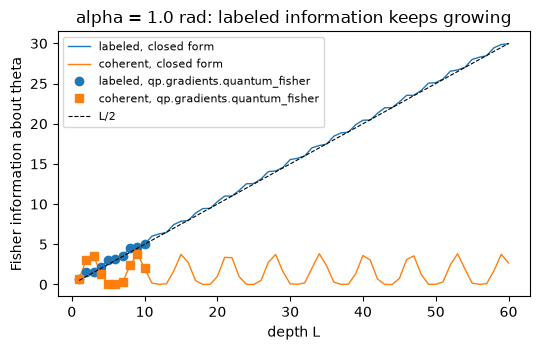

In [7]:
alpha = 1.0
Ls_depth = list(range(1, 11))
lab = [lrc.labeled_qfi(L, alpha) for L in Ls_depth]
coh = [lrc.coherent_qfi(L, alpha) for L in Ls_depth]

from labeled_rc.depth import labeled_closed_form, coherent_closed_form
err = max(max(abs(a - labeled_closed_form(L, alpha)), abs(b - coherent_closed_form(L, alpha)))
          for L, a, b in zip(Ls_depth, lab, coh))
print(f"max |quantum_fisher - closed form| for L = 1..10: {err:.1e}")

L_long = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(L_long, [labeled_closed_form(L, alpha) for L in L_long], color="C0", lw=1, label="labeled, closed form")
ax.plot(L_long, [coherent_closed_form(L, alpha) for L in L_long], color="C1", lw=1, label="coherent, closed form")
ax.plot(Ls_depth, lab, "o", color="C0", label="labeled, qp.gradients.quantum_fisher")
ax.plot(Ls_depth, coh, "s", color="C1", label="coherent, qp.gradients.quantum_fisher")
ax.plot(L_long, L_long / 2, "k--", lw=0.8, label="L/2")
ax.set_xlabel("depth L"); ax.set_ylabel("Fisher information about theta")
ax.set_title(f"alpha = {alpha} rad: labeled information keeps growing")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Two-qubit ZZ crosstalk from owned labels

The multi-qubit extension (`core/multiqubit_zz.py`, experiments 11–13). The target qubit carries
its own coherent error θ₀ and a static ZZ coupling κ to a neighbour. The neighbour is prepared in
|0⟩ or |1⟩ at random each shot (label c), and the target keeps its twirl label s. The ideal signal is
⟨Y⟩ = s · sin(θ₀ + κ c), so the two correlations E[s b] and E[s c b] separate θ₀ from κ.

80,000 shots per point are sampled from the PennyLane circuit on `default.mixed`, with phase damping and
depolarizing noise after the error block and a readout bit flip, and the estimate is debiased by a
measured visibility.

visibility v = 0.9320


kappa=0.00  theta0_hat=+0.1047 [+0.0975, +0.1120]  kappa_hat=+0.0042 [-0.0032, +0.0110]


kappa=0.02  theta0_hat=+0.1020 [+0.0943, +0.1100]  kappa_hat=+0.0172 [+0.0099, +0.0249]


kappa=0.05  theta0_hat=+0.0965 [+0.0888, +0.1024]  kappa_hat=+0.0552 [+0.0485, +0.0621]


kappa=0.10  theta0_hat=+0.1010 [+0.0939, +0.1080]  kappa_hat=+0.1015 [+0.0944, +0.1086]


kappa=0.15  theta0_hat=+0.1036 [+0.0957, +0.1111]  kappa_hat=+0.1509 [+0.1437, +0.1584]
95% intervals containing the true value: 10 of 10


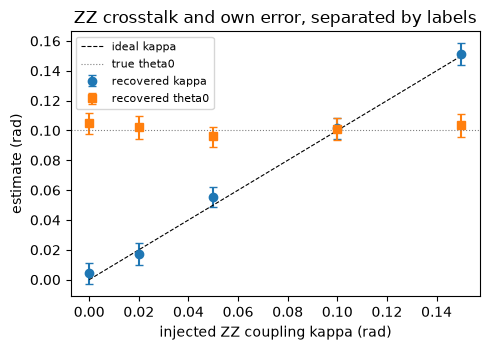

In [8]:
def block_noise(op, **kw):
    qp.PhaseDamping(0.03, wires=op.wires[0])
    qp.DepolarizingChannel(0.01, wires=op.wires[0])

def readout(op, **kw):
    qp.BitFlip(0.02, wires=op.wires)

zz_noise = qp.NoiseModel({qp.noise.op_eq(qp.IsingZZ): block_noise},
                         meas_map={qp.noise.meas_eq(qp.expval) | qp.noise.meas_eq(qp.sample): readout})

dev_zz = qp.device("default.mixed", wires=2, seed=7)
theta0 = 0.10
v_zz = lrc.zz_visibility(dev_zz, 1, noise_model=zz_noise, shots=4000, repeats=10)
print(f"visibility v = {v_zz:.4f}")

kappas = [0.0, 0.02, 0.05, 0.10, 0.15]
rows = []
for k in kappas:
    recs = lrc.sample_zz_records(dev_zz, theta0, [k], shots=80000, seed=int(1000 * k), noise_model=zz_noise)
    r = lrc.recover_zz(recs, v=v_zz, num_boot=300, seed=1)
    rows.append(r)
    (tlo, thi), (klo, khi) = r["ci95"]["theta0"], r["ci95"]["kappa"][2]
    print(f"kappa={k:.2f}  theta0_hat={r['theta0_hat']:+.4f} [{tlo:+.4f}, {thi:+.4f}]  "
          f"kappa_hat={r['kappa_hat'][2]:+.4f} [{klo:+.4f}, {khi:+.4f}]")
covered = sum(r["ci95"]["theta0"][0] <= theta0 <= r["ci95"]["theta0"][1] for r in rows) + \
          sum(r["ci95"]["kappa"][2][0] <= k <= r["ci95"]["kappa"][2][1] for r, k in zip(rows, kappas))
print(f"95% intervals containing the true value: {covered} of {2 * len(rows)}")

fig, ax = plt.subplots(figsize=(5, 3.6))
k_hat = [r["kappa_hat"][2] for r in rows]
k_err = np.array([[r["kappa_hat"][2] - r["ci95"]["kappa"][2][0], r["ci95"]["kappa"][2][1] - r["kappa_hat"][2]] for r in rows]).T
t_hat = [r["theta0_hat"] for r in rows]
t_err = np.array([[r["theta0_hat"] - r["ci95"]["theta0"][0], r["ci95"]["theta0"][1] - r["theta0_hat"]] for r in rows]).T
ax.errorbar(kappas, k_hat, yerr=k_err, fmt="o", capsize=3, label="recovered kappa")
ax.errorbar(kappas, t_hat, yerr=t_err, fmt="s", capsize=3, label="recovered theta0")
ax.plot([0, 0.15], [0, 0.15], "k--", lw=0.8, label="ideal kappa")
ax.axhline(theta0, color="gray", lw=0.8, ls=":", label="true theta0")
ax.set_xlabel("injected ZZ coupling kappa (rad)"); ax.set_ylabel("estimate (rad)")
ax.set_title("ZZ crosstalk and own error, separated by labels")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Re-analysing the IBM hardware records

The paper's single-qubit run on `ibm_marrakesh` (1,620 circuits) writes its per-circuit records to
`hardware/online_data/raw_results.json`. This cell recovers θ from those records with this
package's estimator (no new hardware time) and compares every point estimate with the paper's own
analysis in `hardware/online_data/analysis.json`.

theta*=0.00 L= 1 v=0.993 theta_hat=+0.0048 CI=[-0.0016, +0.0104] n=50
theta*=0.00 L= 2 v=0.993 theta_hat=+0.0025 CI=[-0.0022, +0.0075] n=50
theta*=0.00 L= 4 v=0.993 theta_hat=-0.0030 CI=[-0.0064, +0.0010] n=50
theta*=0.00 L= 8 v=0.994 theta_hat=-0.0020 CI=[-0.0033, -0.0007] n=50
theta*=0.00 L=16 v=0.993 theta_hat=-0.0010 CI=[-0.0028, +0.0009] n=50
theta*=0.00 L=32 v=0.994 theta_hat=-0.0000 CI=[-0.0012, +0.0011] n=50
theta*=0.05 L= 1 v=0.993 theta_hat=+0.0538 CI=[+0.0483, +0.0590] n=50
theta*=0.05 L= 2 v=0.993 theta_hat=+0.0468 CI=[+0.0411, +0.0529] n=50
theta*=0.05 L= 4 v=0.993 theta_hat=+0.0502 CI=[+0.0469, +0.0534] n=50
theta*=0.05 L= 8 v=0.994 theta_hat=+0.0463 CI=[+0.0441, +0.0487] n=50
theta*=0.05 L=16 v=0.993 theta_hat=+0.0491 CI=[+0.0475, +0.0506] n=50
theta*=0.05 L=32 v=0.994 theta_hat=+0.0493 CI=[+0.0483, +0.0504] n=50
theta*=0.10 L= 1 v=0.993 theta_hat=+0.0996 CI=[+0.0922, +0.1074] n=50
theta*=0.10 L= 2 v=0.993 theta_hat=+0.1026 CI=[+0.0987, +0.1064] n=50
theta*=0.10 L= 4 v=0

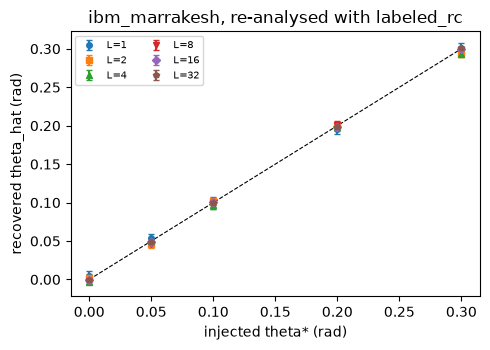

In [9]:
import json

path = os.path.join("..", "..", "hardware", "online_data", "raw_results.json")
paper_path = os.path.join("..", "..", "hardware", "online_data", "analysis.json")
if os.path.exists(path):
    table = lrc.recover_from_records(lrc.load_records(path))
    paper = json.load(open(paper_path))["results"] if os.path.exists(paper_path) else {}
    worst, agree = 0.0, 0.0
    for (th, L), r in table.items():
        worst = max(worst, abs(r["theta_hat"] - th))
        key = f"theta{th:.3f}_L{L}"
        if key in paper:
            agree = max(agree, abs(r["theta_hat"] - paper[key]["theta_hat"]))
        print(f"theta*={th:.2f} L={L:2d} v={r['visibility']:.3f} theta_hat={r['theta_hat']:+.4f} "
              f"CI=[{r['ci95'][0]:+.4f}, {r['ci95'][1]:+.4f}] n={r['instances']}")
    print(f"max |theta_hat - theta*| over the hardware grid = {worst:.4f} rad")
    if paper:
        print(f"max |theta_hat - paper analysis| = {agree:.1e} rad")

    fig, ax = plt.subplots(figsize=(5, 3.6))
    for L, mk in zip(sorted({L for _, L in table}), "os^vDp"):
        ths = sorted(th for th, LL in table if LL == L)
        est = [table[(th, L)]["theta_hat"] for th in ths]
        err = np.array([[table[(th, L)]["theta_hat"] - table[(th, L)]["ci95"][0],
                         table[(th, L)]["ci95"][1] - table[(th, L)]["theta_hat"]] for th in ths]).T
        ax.errorbar(ths, est, yerr=err, fmt=mk, ms=4, capsize=2, label=f"L={L}")
    ax.plot([0, 0.3], [0, 0.3], "k--", lw=0.8)
    ax.set_xlabel("injected theta* (rad)"); ax.set_ylabel("recovered theta_hat (rad)")
    ax.set_title("ibm_marrakesh, re-analysed with labeled_rc")
    ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()
else:
    print("hardware/online_data/raw_results.json not found: hardware re-analysis skipped.")

## Summary

- `pauli_twirl` adds standard Pauli twirling (randomized compiling) for CNOT/CZ to PennyLane.
- `sign_label_twirl` keeps the twirl labels, and the labeled estimator recovers the coherent error
  angle that standard RC averages away, under noise and with finite shots.
- The conservation law holds to machine precision with PennyLane autodiff and with
  `qp.gradients.classical_fisher` / `quantum_fisher`; the paper's closed forms are confirmed as
  leading order in θ.
- The depth theorem (labeled information ~ L/2, coherent bounded) is reproduced with
  `qp.gradients.quantum_fisher`, matching Oracles O2/O3.
- The two-qubit ZZ-crosstalk recovery runs end to end on sampled, noisy PennyLane data.
- Re-analysing the `ibm_marrakesh` records reproduces the paper's estimates.

Tests: `pytest pennylane_impl/tests` (frames, transforms, conservation, depth, crosstalk, noisy
recovery, hardware re-analysis, and cross-checks against the repository's numpy engine).